In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md
!pip install rdkit
from rdkit import Chem

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

# Why am I creating this notebook ? 
The first day that I joined this competition, I encountered lots of different expressions that I didn't know the meaning of them. I was confused, and I thought others might be as confused as well. 

The goal of this notebook is simple: I will gather the domain knowledge that we need for this competition , so you don't have to. I will update this notebook regularly. I try to write simply and if something is hard to understand I will tell it as a story with covering examples.

**Note** : I'm not a chemist, all the things that I have gathered are through searching + LLMs. I tried to validate the information, but even with that, some might be incorrect. If you saw anything which is misleading, tell me to correct it so others don't get confused. Thanks

# Update
## EDA

**I just did a full EDA on the dataset. make sure you [check it out](https://www.kaggle.com/code/mohammadhmozafary/casmi-2026-eda-you-need)**

In [ ]:
df = pd.read_parquet("/kaggle/input/competitions/enveda-CASMI26-molecule-id-mass-spectra/train.parquet")

In [ ]:
df.head()

In [ ]:
df.columns

# What are we trying to predict?


<p> Our main goal in this competition is to predict <code>normalized_smiles</code> feature.

## What is SMILES?
In chemistry, SMILES stands for **Simplified Molecular Input Line Entry System**. It is a text notation used to represent the structure of a molecule using ASCII characters. 

## SMILES Representation
There are different things that SMILES represents. we have:

1. Atoms - Aromatic Atoms
2. Bonds
3. Chains
4. Branches / Multiple Branches
5. Rings - Ring Numbers
6. Charges

7. Stereochemistry


### Atoms - Aromatic Atoms
We write the element symbol . for example:

C = carbon

N  = nitrogen

O = Oxygen

Also the atom capitalization **matters**.
C means **aliphatic** carbon. whereas c means **aromatic** carbon.

Uppercase generally represents the ordinary/aliphatic form, while lowercase represents aromatic atoms.

### SMILES Bonds

A bond is represented using one of the symbols `.` `-` `=` `#` 

1. Single Bonds : Use `-`  which is mostly omitted. example : C-C which is the same as CC

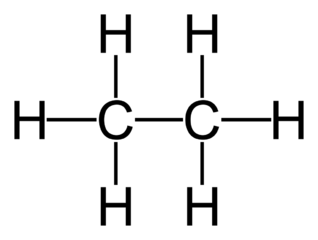


3. Double Bonds : Use `=`, C=C : Ethene

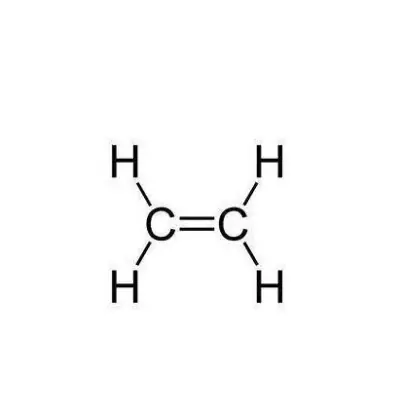


4. Triple Bonds : Use `#` . C#C : Ethyne

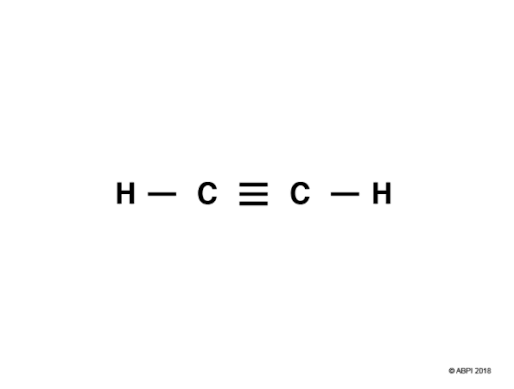



5. Non Bonds: indicated with `.` , to indicate that two parts are not bonded together. For Example : [Na+].[Cl-]

   



### SMILES Chains
Atoms written next to each other are connected.

For example:

CCC means C-C-C which is propane and CCCC means C-C-C-C which is butane

### SMILES Branches
Parentheses `( )` indicate a branch.

The first atom within the parentheses and the first atom after the parenthesized group are bonded to the same branch point atom

For example : CC(C)C is Isobutane (2-methylpropane)

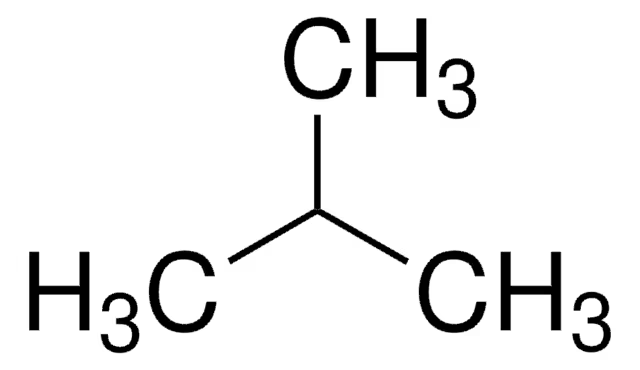

Another example is : CC(C)CC which is Isopentane (2-methylbutane)

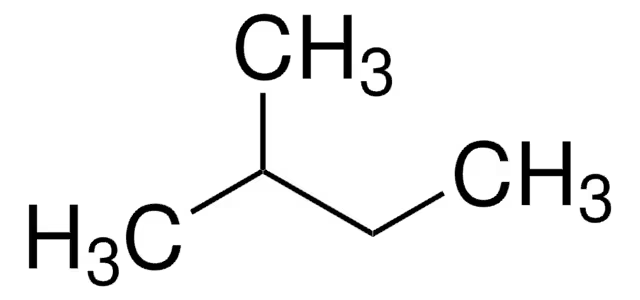

## SMILES Rings
SMILES uses numbers to indicate that two atoms are connected to form a ring.

Example:

C`1`CCCCC`1`

Which is cyclohexane
The two 1s indicate the ring closure. 

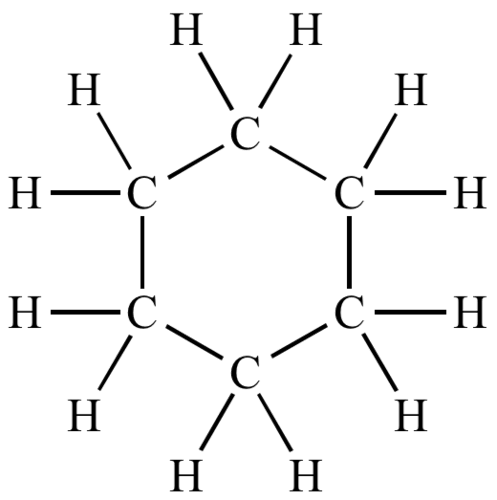

A ring number normally appears twice.

The first 1 says:

"Start a ring connection here."

The second 1 says:

"Close that ring connection here."

### Different ring numbers

We can use different numbers for multiple rings.

For example:

C1CC2CCC1C2

The 1 pair describes one ring closure and the 2 pair describes another.
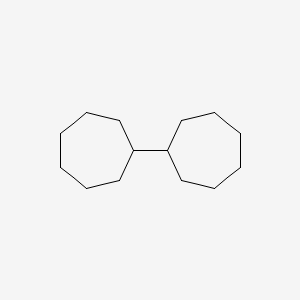

## SMILES Charges
in the SMILES representation charges go inside square brackets `[]`.

Positive charge: `[NH4+]` which is the ammonium ion.

Negative charge: `[O-]`

Example:  `C[NH3+]` which represents a protonated amine.

Another example: `C(=O)[O-]` which represents a carboxylate group

## What is Stereochemistry?
Stereochemistry is about the **3D arrangement** of atoms in a molecule.

Two molecules can have:

the same atoms
the same connections/bonds
but different 3D arrangements

Those molecules can behave differently chemically and biologically.

For example for lactic acid has two possible 3D arrangements.

      Arrangement A       Arrangement B

          OH                   OH
           \                   /
            C                 C
           / \               / \
        CH3   H            H   CH3

They have the same formula and connectivity, but their 3D arrangements are mirror images.

## How does Stereochemistry appear in SMILES?

SMILES can encode stereochemistry using `@` and `@@`

For example:

`N[C@H](C)C(=O)O` and `N[C@@H](C)C(=O)O`

can represent different stereochemical configurations.

The `@` and `@@` tell software such as RDKit about the 3D orientation around a stereocenter.

There is also stereochemistry around double bonds, represented using `/` and `\`:

`F/C=C/F` versus `F/C=C\F`

These can represent different geometric arrangements around the double bond.

## Example from our dataset
To further understand these representations, we will give an example from our dataset. We will use RDKit which is made explicitly for such tasks.

In [ ]:
smiles_sample = df['normalized_smiles'].sample().values[0]
print("sample molocule SMILES: \n",smiles_sample)

In [ ]:
mol = Chem.MolFromSmiles(smiles_sample)

### Investigating the atoms of our molocule
Let's first draw this molecule as a graph:

In [ ]:
from rdkit.Chem import Draw

img = Draw.MolToImage(mol)
display(img)

Then let's extract the atoms and bonds as a dataframe:

In [ ]:
molecule = {
    "smiles": smiles_sample,
    "atoms": {},
    "bonds": {}
}

# -------------------------
# Atoms
# -------------------------
for atom in mol.GetAtoms():
    atom_idx = atom.GetIdx()

    molecule["atoms"][atom_idx] = {
        "symbol": atom.GetSymbol(),
        "atomic_num": atom.GetAtomicNum(),
        "degree": atom.GetDegree(),
        "is_aromatic": atom.GetIsAromatic(),
        "formal_charge": atom.GetFormalCharge(),
    }


# -------------------------
# Bonds
# -------------------------
for bond in mol.GetBonds():
    bond_idx = bond.GetIdx()

    molecule["bonds"][bond_idx] = {
        "begin_atom": bond.GetBeginAtomIdx(),
        "end_atom": bond.GetEndAtomIdx(),
        "bond_type": str(bond.GetBondType()),
        "is_aromatic": bond.GetIsAromatic(),
        "is_in_ring": bond.IsInRing(),
    }
    
atoms_df = pd.DataFrame.from_dict(molecule['atoms'], orient="index")
atoms_df.index.name = "atom_idx"
bonds_df = pd.DataFrame.from_dict(molecule['bonds'], orient="index")
atoms_df.index.name = "bond_idx"


In [ ]:
atoms_df

In [ ]:
bonds_df

# What is Da?

Da (Dalton) is a unit used to measure how heavy atoms and molecules are — like grams measure the weight of everyday objects.

Example: A water molecule (H₂O) has a mass of about 18 Da, meaning it has a tiny mass of 18 daltons.

Think of Da as a way to weigh things that are too small to see!

# About InChI and InChIKey

## What is InChI?

**InChI** stands for **International Chemical Identifier**.

It is a standardized textual representation of a chemical structure.
"
You can think of the relationship like this:

**SMILES → Chemical Structure → InChI → InChIKey**

For example, caffeine can be represented as:

```text
SMILES:
Cn1c(=O)c2c(ncn2C)n(C)c1=O

InChI:
InChI=1S/C8H10N4O2/c1-10-4-9-6-7(10)12(3)...
```

The InChI contains multiple layers describing different properties of the molecule.

---

## What is an InChIKey?

An **InChIKey** is a short, fixed-length identifier generated from an InChI.

For example:

```text
RYYVLZVUVIJVGH-UHFFFAOYSA-N
```

An InChIKey is much shorter than the corresponding InChI, which makes it convenient for:

* Searching chemical databases
* Comparing molecular identifiers
* Joining chemical datasets
* Detecting duplicate structures
* Linking records between databases

An InChIKey is **not the chemical structure itself**. It is a compact identifier derived from the structure.

---

## Structure of an InChIKey

A standard InChIKey has 27 characters and follows this general pattern:

```text
XXXXXXXXXXXXXX-YYYYYYYYYY-Z
```

For example:

```text
RYYVLZVUVIJVGH-UHFFFAOYSA-N
```

It can be separated into three parts:

```text
RYYVLZVUVIJVGH - UHFFFAOYSA - N
       │                │       │
       │                │       └── version / protonation information
       │                │
       │                └────────── stereochemical and other layers
       │
       └─────────────────────────── connectivity layer
```

The exact interpretation of every character is defined by the InChI specification, but the most important part for dataset analysis is the **first 14 characters**.

---

## What is InChIKey14?

**InChIKey14** usually refers to the **first 14 characters of an InChIKey**.

For example:

```text
Full InChIKey:

RYYVLZVUVIJVGH-UHFFFAOYSA-N
^^^^^^^^^^^^^^

InChIKey14:

RYYVLZVUVIJVGH
```

The first 14 characters correspond to the **connectivity layer** of the InChIKey.

This means that InChIKey14 can be useful for grouping molecules that have the same molecular connectivity.

---

## Why is InChIKey14 useful?

Consider two molecules with the same connectivity but different stereochemistry:

```text
Molecule A:
N[C@H](C)C(=O)O

Molecule B:
N[C@@H](C)C(=O)O
```

These molecules have the same connectivity but different stereochemical configurations.

Their:

* **InChIKey14** can be the same
* **Full InChIKey** can be different

Conceptually:

```text
Same connectivity
       ↓
Same InChIKey14

Different stereochemistry
       ↓
Different full InChIKey
```

This makes InChIKey14 useful when analyzing **stereoisomers** in a dataset.

---

## SMILES vs InChI vs InChIKey

| Identifier     | Purpose                                                 |
| -------------- | ------------------------------------------------------- |
| **SMILES**     | Represents a molecular structure as a string            |
| **InChI**      | Standardized representation of a molecular structure    |
| **InChIKey**   | Compact identifier derived from an InChI                |
| **InChIKey14** | First 14 characters representing molecular connectivity |

---


## Example on InchiKey
Two useful analyses can be driven used by inchikeys : 
1. Finding duplicate molecules 
2. Find molecules with the same connectivity using InChIKey14

## Finding duplicate molecules using InChiKey

In [ ]:
print(f"There are {df['inchikey'].nunique()} unique molecules in the train set")
print(f"Number of duplicated molecules: {df["inchikey"].duplicated().sum()}")
duplicate_rate = (
    df["inchikey"].duplicated().sum() / len(df)
)

print(f"molecules duplicate rate: {duplicate_rate:.2%}")

basically this shows that 90%  of the molecules are duplicated !

## Find molecules with the same connectivity using InChIKey14

In [ ]:
summary = (
    df.groupby("inchikey14")
      .agg(
          n_records=("inchikey", "size"),
          n_unique_inchikey=("inchikey", "nunique")
      )
      .reset_index()
)
summary["type"] = summary.apply(
    lambda row:
        "real_duplicates"
        if row["n_unique_inchikey"] == 1
        else "same_connectivity",
    axis=1
)

summary["type"] = summary.apply(
    lambda row:
        "unique"
        if row["n_records"] == 1
        else (
            "real_duplicates"
            if row["n_unique_inchikey"] == 1
            else "same_connectivity"
        ),
    axis=1
)


In [ ]:
summary['type'].value_counts()

The dataset contains 258,638 exact duplicates, 17,033 unique molecules, and 139 molecules sharing the same connectivity but having different InChIKeys. This indicates that most repeated records are exact molecular duplicates, while only a small number represent different structures with the same connectivity.

# About Molecular Formula
I won't write much about this because most of us know what is a molecular formula. Only thing worth mentioning is the differences between SMILES and Molecular formula :

|                 | Molecular formula        | SMILES                  |
| --------------- | ------------------------ | ----------------------- |
| Describes       | Which atoms and how many | How atoms are connected |
| Example         | `C2H6O`                  | `CCO`                   |
| Connectivity    | No                       | Yes                     |
| Branches        | No                       | Yes                     |
| Rings           | No                       | Yes                     |
| Bond types      | No                       | Yes                     |
| Stereochemistry | No                       | Can encode it           |


basically : molecular formula cannot uniquely identify a molecule, while a properly interpreted SMILES contains much more structural information.

## Basic EDA on molecular formula

### 1. Molecular formula frequency

In [ ]:
formula_counts = df["molecular_formula"].value_counts()
formula_counts.head(20)

### 2. Formula vs. number of unique molecules
This is particularly useful because different molecules can have the same molecular formula. 

In [ ]:
formula_analysis = (
    df.groupby("molecular_formula")
      .agg(
          n_records=("molecular_formula", "size"),
          n_unique_molecules=("inchikey", "nunique")
      )
      .reset_index()
      .sort_values("n_unique_molecules", ascending=False)
)

formula_analysis.head(20)

# What are our predictors? What do they mean?


Let's explain our features with a short story.
## A day in the lab: the story behind each column

Dr. Mira has a small vial on her bench. Inside is a pinch of an unknown compound from a plant extract. Her job is to find out what it is. For the story, say the mystery molecule is `caffeine`, though she doesn't know that yet. The numbers below are illustrative. 

We will also investigate the caffeine in our train data along Mira

In [ ]:

caf = df[df.inchikey14 == 'RYYVLZVUVIJVGH']


In [ ]:
print(f"we have {caf.shape[0]} numbers of caffeine molecules in our train set")
print(50*"-")
print("Our caffeine molecules counts grouped by inchikey:")
print(caf['inchikey'].value_counts())

* We only have two types of caffeine molecules (the InChiKeys are unique identifiers). Out of 645 caffeine molecules, 644 of them have the same structure and 1 of them is different from the rest 644 samples.

## Scene 1. Choosing the machine (`instrument_type`)

Mira walks to a large Bruker timsTOF and types its name into her lab notebook. This is `instrument_type`.

It matters because every instrument has its own quirks, like cameras with different lenses. A **timsTOF** breaks molecules and records the pieces a little differently from an **Orbitrap** down the hall. 

**In the competition, all test spectra come from the timsTOF**, but the training data comes from dozens of machines, written as messy free text ("Orbitrap Fusion", "QTOF", "LC-ESI-QFT", or nothing at all). A model trained on all of it has to cope with the "different cameras" problem.

## 1.1. Dataset Example - Caffeine check: Instrument Type

In [ ]:
## Let's see what insturment were used for our caffeine
print("Our caffeine molecules counts grouped by instrument type:")
caf['instrument_type'].value_counts()

* As you can see, our caffeines were mostly investigated with `Orbitrap` and `LC-ESI-ITFT` machines.


## Scene 2. Choosing a charge sign (`ionization_mode`)

**The machine can only handle charged molecules**, so Mira has to decide which sign to give them. She flips the switch to **positive** because her sample probably has nitrogen, and nitrogen likes to grab a proton.

That switch is `ionization_mode`: `positive` or `negative`. Later, she may run the sample again in negative mode. The spectrum will look quite different, because different bonds break. They are two separate experiments, and a model should never blend them without knowing which is which.

## 2.1. Dataset Example  - Caffeine check: Ionization mode

In [ ]:
print("Our caffeine molecules counts grouped by ionization mode:")
print()
print(caf['ionization_mode'].value_counts())

*  Out of our 645 caffeine molecules, 628 of them were charged positively and 17 of them were charged negatively.

## Scene 3. The molecule picks up its charge (`adduct`, `adduct_orig`)

The sample is sprayed into a fine mist. Each caffeine molecule bumps into something and sticks to it. Most grab a proton `([M+H]+)`, but a few grab a stray sodium from the glassware `([M+Na]+)`.

She records which one each measurement was. That label is the `adduct`: the exact way the molecule got its charge. It matters because each adduct changes the measured weight by a known amount, and changes how the molecule later breaks.

Now meet Dr. Okafor in a lab across the world. She writes the same adduct as `M+H`, `[M+H]1+`, or `MH+`. Different labs, different handwriting. When the dataset's curator collects everything, they translate each into one standard spelling. The standardized version is `adduct`, and the string exactly as the lab wrote it is `adduct_orig`, kept for debugging when something looks odd. In the test set, the standardized one is always one of ten.

## 3.1. Dataset Example - Caffeine check: Adduct check

In [ ]:
print("Our caffeine molecules counts grouped by adduct:")
print(caf['adduct'].value_counts())
print(50*"-")
print("Our caffeine molecules counts grouped by adduct_orig:")
print(caf['adduct_orig'].value_counts())

*  We had `628` molecules with `positive` charge.
*  Out of these `628` mols, `474`  of them are charged with `[M+H]+`, `149` with `[M+Na]+` ,`1` with `[M-H2O+H]+` and `1` with `[M+K]+`. This adds up to `625`. Probably there are some conflicts in the data.
*  We had `17` molecules with negative charge. but the `adduct` indicates that there are `20` molecules charged with `[M-H]-`.




## Scene 4. Weighing the whole molecule (`precursor_mz`, `precursor_error_ppm`)

The first thing the machine does is weigh the intact charged molecule. The reading is `precursor_mz`: 195.0877.

Mira does the subtraction in her head. It's `[M+H]+`, so she subtracts the proton's `1.00728` and gets a neutral weight of about `194.0804`. Only a few combinations of atoms add up to that, and `C₈H₁₀N₄O₂` is one of them.

Now jump forward a year. A curator is building the dataset and knows the answer is `caffeine`, whose true weight is `194.0804`. They ask, "If this really is caffeine as `[M+H]+`, where should the machine have read?" The answer is `195.0877`. How far off was the actual reading? They write that gap as `precursor_error_ppm`, in parts per million.

* **195.0877** vs **195.0877**: error near 0 ppm. The label agrees with the measurement.
* Suppose instead the reading was **195.0900**. That's about 12 ppm off, which is suspicious.
* Suppose it was **217.0696**. That's 100,000+ ppm off. The spectrum was actually sodium, mislabeled as proton.

So this column is a **lie detector for labels**. In training, large values mean the structure or the adduct is probably wrong, and you should drop or distrust those rows. The competition already removed such rows from the test set, so it doesn't appear there.

## 4.1. Dataset Example  - Caffeine check: Molecule weights and errors

In [ ]:
caf['precursor_error_ppm'].describe()

**`precursor_mz`** (645 spectra)
- The median is about 195.089, which matches the expected `[M+H]+` value for caffeine (195.0877). So most rows are protonated caffeine, as expected.
- The min (177.078) and max (233.044) are not errors. They match `[M-H2O+H]+` (177.077) and `[M+K]+` (233.044), so the range is just different adducts of the same molecule.
- The mean (200.1) is pulled up by the sodium and potassium rows, so the median is the better summary.
- The 75th percentile (195.21) is about 0.12 Da above the expected value. That is far too large for a high-resolution instrument, so some libraries may report lower-precision masses.

In [ ]:
caf['precursor_mz'].describe()



**`precursor_error_ppm`** (642 of 645 non-null)
- The median error is about 2.6 ppm, which is good. But a quarter of the rows are above 9 ppm.
- The max is 15,233 ppm (about 3 Da off), and the mean (106) is dominated by such outliers. For this column, trust the median and percentiles, not the mean.
- 3 rows are null.

**What to investigate**
1. Error by `ingest_lib`: do a few libraries cause the bad rows?
2. Error by `adduct`: is any adduct systematically worse?
3. Rows with error above 10 or 20 ppm: wrong adduct, wrong label, or a low-resolution instrument?
4. The 3 null-error rows: why are they missing?
5. How many rows each ppm cutoff (5, 10, 20) would drop, and from which libraries.

## Scene 5. The smash (`collision_energy_ev`, `collision_energy_orig`, `collision_energy_orig_units`)

Next the machine isolates the caffeine ions and fires them into a cloud of nitrogen gas. A dial controls how hard. Mira runs three experiments, at `20`, `40` and `60 eV` (electron volts, an absolute unit of energy).

* At `20 eV`, caffeine mostly survives, with a few big fragments.
* At `60 eV`, it shatters into many small pieces.

The settings she records are the `collision energy`. She also does a fourth run that cycles through 20, 40 and 60 within one acquisition and saves them merged into one spectrum. That is why the column can be a list, like `[20, 40, 60]`.

Now Dr. Okafor's lab uses a different kind of machine, and its dial isn't in eV at all. It reads in **NCE**, a percentage-style scale, and her notebook says `35HCD` or `[20 40 60]`. A colleague elsewhere wrote `6V` (raw volts). Three labs, three languages.

The curator keeps three columns to cope with this:

| Column | What it holds | Why |
|---|---|---|
| `collision_energy_orig` | The text exactly as the lab wrote it (`35HCD`, `6V`) | Nothing lost, in case the conversion was wrong |
| `collision_energy_orig_units` | The curator's decision: `eV`, `NCE`, `V`, or `unknown` | Tells you what the number means |
| `collision_energy_ev` | The curator's best conversion to eV | One common scale to model with |

NCE to eV depends on the molecule's weight and on the machine's tuning, so that conversion is approximate, and it is null where the units couldn't be figured out. For modeling, use `collision_energy_ev`. Use the other two only to investigate suspicious rows. In the test set, units are always eV.

## 5.1. Dataset Example - Caffeine check: collision energy

In [ ]:
caf['collision_energy_orig'].value_counts()

In [ ]:
caf['collision_energy_orig'].describe()

In [ ]:
caf['collision_energy_orig_units'].value_counts()

In [ ]:
caf['collision_energy_ev'].value_counts()


**What the numbers show**
- `collision_energy_orig` is missing for 94 of 645 rows (551 non-null), and it comes in many formats: `10`, `60.0`, `20;40;60`, `[20.0, 45.0, 60.0, 40.0]`. It is free text and needs parsing before use.
- Units are mixed: 356 NCE (55%), 168 eV, 19 V and 102 unknown. Most caffeine rows were therefore **converted** to eV, not measured in eV.
- The odd values in `collision_energy_ev` (3.9, 7.8, 15.6, 23.4, 31.2) look like NCE values scaled by `precursor_mz / 500`. For caffeine `[M+H]+`, 195.09/500 = 0.39, so NCE 10 gives 3.9, NCE 20 gives 7.8 and NCE 60 gives 23.4. The 4.3, 8.7, 17.4 and 26.0 group matches the same NCE steps on the sodium adduct (217.07/500 = 0.434). So the same "NCE 20" becomes 7.8 eV or 8.7 eV depending on the adduct.
- The clean values (10.0, 20.0, 40.0, 60.0, 80.0) are probably native eV. The raw string `10` alone can't tell you whether it means 10 eV or 10 NCE (3.9 eV), so the units column is essential.
- Merged spectra appear as lists, e.g. `[7.8, 11.7, 15.6]` (consistent with NCE 20, 30, 40 merged) and `[20.0, 40.0, 60.0]`.
- Values of 90 to 150 eV (`[120.0]`, `[150.0]`) are unusually high for caffeine and may be voltages treated as eV.
- `value_counts` shows `[7.8, 11.7, 15.6]` and `[14.5, 21.8]` several times, each with count 1. The list-valued entries are not being grouped (probably arrays), so counts for merged spectra are unreliable until you turn them into tuples.

**What to investigate**
1. Which rows have a null `collision_energy_ev`, and is that the same set as unknown units?
2. Does `ev ≈ NCE × precursor_mz / 500` hold for every NCE row?
3. How many rows are merged, and how many energies each?
4. Which library and units produce the values above 80 eV?
5. How do eV rows (the ones that match the test file's convention) compare with NCE-converted rows for the same molecule? Do spectra at "the same" energy look alike?

## Scene 6. The detector records the pieces (`ms2_mzs`, `ms2_normalized_intensities`, `base_peak_intensity`, `num_peaks`)

After the smash, the fragments fly to the detector. It counts how many pieces of each weight arrive. Mira sees a bar chart:

* Weights go along the bottom: `83.06`, `110.07`, `138.07`, `195.09`. This is `ms2_mzs`, the list of fragment weights. The gaps between them are clues. For example, 195.09 − 138.07 = 57.02, which is a chunk caffeine commonly throws off.
* Heights go up the side. The raw counts say, for example, 12,000 / 31,000 / 52,000 / 20,000. The tallest bar is 52,000. This raw height is `base_peak_intensity`, how loud the signal was.
* Raw counts are awkward to compare between experiments, so the curator rescales so the tallest bar equals 1.0: 0.23 / 0.60 / 1.00 / 0.38. These are `ms2_normalized_intensities`, paired one-to-one with the weights. The tallest bar is called the base peak.
* She counts four bars. That count is `num_peaks`.

Why each of these matters:

* `base_peak_intensity` is the volume knob. A 52,000 spectrum was loud and clear, so its small peaks are probably real. An 8,000 spectrum is faint, and its small peaks may be static. The test set already dropped spectra below 1,000. Use the value to decide how much to trust each spectrum, or when to throw away tiny peaks. Because normalization erases absolute size, this column is the only record of signal strength.
* `num_peaks` is a quick quality gauge. A spectrum with 2 peaks says almost nothing about the structure. One with thousands of peaks is likely full of noise. Both extremes are usually cleaned up or capped.
* Decimals matter in `ms2_mzs`. The decimals are chemically informative, since atoms have slightly different exact weights. Rounding throws away real information.

## 6.1. Dataset Example - Caffeine check: Pieces and Fragments

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. pick one caffeine spectrum that has a raw base peak value and a handful of peaks
cand = caf[caf.base_peak_intensity.notna() & caf.num_peaks.between(5, 30)]
row = cand.iloc[0]

mz = np.asarray(row.ms2_mzs, dtype=float)
norm = np.asarray(row.ms2_normalized_intensities, dtype=float)
bpi = row.base_peak_intensity

print(f"library: {row.ingest_lib} | adduct: {row.adduct} | precursor_mz: {row.precursor_mz:.4f}")
print(f"base_peak_intensity: {bpi:,.0f}")

# 2. recover raw counts: raw = normalized * base_peak_intensity
raw = norm * bpi

peaks = pd.DataFrame({'mz': mz.round(4), 'normalized': norm.round(3), 'raw_count': raw.round(0)})
display(peaks)

# 3. check the claims from the story
print("\nmax normalized value == 1.0 ?", np.isclose(norm.max(), 1.0))
print("max raw count == base_peak_intensity ?", np.isclose(raw.max(), bpi))
print("num_peaks == len(ms2_mzs) ?", row.num_peaks == len(mz))
print("normalizing the raw counts again gives back the same values ?", np.allclose(raw / raw.max(), norm))

# 4. plot both views side by side: same shape, different y-axis
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5), sharex=True)
ax[0].vlines(mz, 0, raw, color='tab:blue');  ax[0].set_title('raw counts (loudness kept)')
ax[1].vlines(mz, 0, norm, color='tab:orange'); ax[1].set_title('normalized (tallest = 1.0)')
for a in ax:
    a.axvline(row.precursor_mz, color='red', ls='--', lw=1)   # precursor position
    a.set_xlabel('m/z')
plt.tight_layout(); plt.show()

# About different instrument types

In [ ]:
df['instrument_type'].value_counts()

We have 82 instrument types in our train set. These can be divided into 8 families.
1. timsTOF, the competition organizer has mentioned that the test set only contains this type of machine
2. orbitrap_ft family.
3. tof_qtof family.
4. triple_quad family
5. ion_trap family
6. sector , unknown and others families.
The differences between each family is represented below:

## Instrument families

| Family | 1. How precisely does it weigh? | 2. How does it break the molecule? | 3. How is smash strength given? |
|---|---|---|---|
| **`timstof`** (test set) | High. Resolution roughly 40,000 to 50,000, error around 1 to 3 ppm. Your own data shows a median of about 1.4 ppm for `[M+H]+`. | Beam-type collision cell: ions are accelerated and smashed in one go, so you get rich, broad fragment sets. It also separates ions by shape (ion mobility), which is not in this data. | **eV**, an absolute energy. Merged lists like `[20, 40, 60, 80]` are common. |
| **`orbitrap_ft`** | Very high. Resolution 15,000 to 240,000+ (names like "Res 70k" show the setting), error usually under 3 ppm. | Mostly HCD, which is also beam-type and looks similar to timsTOF but with different intensity patterns. **Exception:** the `ITFT` machines (ion trap plus Orbitrap) may fragment in the trap, which gives a different, sparser pattern. | **NCE**, a percentage whose real energy depends on the molecule's mass and the machine's tuning. The dataset converts it to eV only approximately. |
| **`tof_qtof`** | Good. Resolution about 20,000 to 60,000, error 1 to 5 ppm. | Beam-type, similar in spirit to timsTOF. Includes Bruker Maxis and impact HD (same company, but not timsTOF) and Waters Synapt. | **eV** or collision **voltage**. Mostly native eV, so reasonably comparable to the test. |
| **`triple_quad`** | Low. Unit resolution (about 0.7 Da peak width), so masses are often stated to one or two decimals. | Beam-type in the middle quadrupole. Built for measuring known targets, not for scanning many fragments. | eV or volts. The Quattro names even embed the value (`:10eV`). |
| **`ion_trap`** | Low. Unit resolution, with a "low-mass cutoff" that loses the smallest fragments. | Resonance CID: ions are shaken gently and break at the weakest bond, usually giving fewer, bigger fragments than beam-type machines. | Often a **normalized %** or arbitrary units, with no true eV equivalent. |
| **`sector`** (342 rows) | Varies. Old instruments. | Very high-energy collisions, a different regime entirely. | Not comparable. |
| **`unknown`** (34,699 rows) | Unknown | Unknown | Unknown |
| **`other`** (134 rows) | Unknown | Single quadrupole or in-source fragmentation, not normal MS/MS. | Unknown |

In [ ]:
import re

def instrument_family(x):
    s = '' if pd.isna(x) else str(x).strip().lower()
    if s in ('', 'nan', 'n/a', 'na', 'none', 'unknown', 'lc-esi-hrms'):    return 'unknown'
    if 'tims' in s:                                                         return 'timstof'
    if re.search(r'orbitrap|exactive|qft|itft|qehf|hybrid ft|\bft\b', s):   return 'orbitrap_ft'
    if re.search(r'q-?tof|maxis|impact|synapt|tof', s):                     return 'tof_qtof'
    if re.search(r'ion ?trap|iontrap|\bqit\b|-q?it$|^it$|^lit$|ltq', s):    return 'ion_trap'
    if re.search(r'qqq|\bqq\b|-qq$|quattro|triple', s):                     return 'triple_quad'
    if re.search(r'fab|ebeb|sector|-be$', s):                               return 'sector'
    return 'other'

def ion_source(x):
    s = '' if pd.isna(x) else str(x).lower()
    if 'maldi' in s:                          return 'maldi'
    if re.search(r'gc-|-ei-', s):             return 'gc_ei'
    if re.search(r'fab|si-be|in source', s):  return 'fab_or_in_source'
    return 'lc_or_unspecified'

df['instr_family'] = df.instrument_type.map(instrument_family)
df['ion_source']   = df.instrument_type.map(ion_source)

In [ ]:
df['instr_family'].value_counts()

# This notebook will be updated regularly 
## Remaining Topics to cover
1. ingest_lib , what is it ? what are the differences? how do they affect our predictions?
2. COCONUT , PubChem , what are they ? how to use them efficiently?
3. External data sources, what do they cover? can we use them for our task? which ones are better to use? which one needs to be used carefuly? 
